In [14]:
import os
from pathlib import Path

DATASET_DIR = Path("/kaggle/input/ip02-dataset")

if not DATASET_DIR.exists():
    print("Dataset folder not found.")
    print("Available folders:")
    for p in Path("/kaggle/input/notebooks/kushagranull/crop-yield-prediction").iterdir():
        print(p)
else:
    print("Dataset:", DATASET_DIR)

    for root, dirs, files in os.walk(DATASET_DIR):
        level = len(Path(root).relative_to(DATASET_DIR).parts)

        if level > 3:
            dirs[:] = []
            continue

        print(
            "  " * level,
            Path(root).name,
            "| Subfolders:", len(dirs),
            "| Files:", len(files)
        )

Dataset folder not found.
Available folders:
/kaggle/input/notebooks/kushagranull/crop-yield-prediction/__notebook__.ipynb
/kaggle/input/notebooks/kushagranull/crop-yield-prediction/__output__.json
/kaggle/input/notebooks/kushagranull/crop-yield-prediction/__results__.html
/kaggle/input/notebooks/kushagranull/crop-yield-prediction/__results___files
/kaggle/input/notebooks/kushagranull/crop-yield-prediction/__resultx__.html
/kaggle/input/notebooks/kushagranull/crop-yield-prediction/custom.css


TensorFlow version: 2.20.0
GPU devices: []

SEARCHING FOR THE IP102 DATASET
Not found: /kaggle/input/ip02-dataset
/kaggle/input/notebooks/kushagranull/crop-yield-prediction -> 5 images
/kaggle/input -> 75227 images

Selected dataset root: /kaggle/input
Images discovered: 75227
Class-name file found: True
Names in classes.txt: 102

Number of detected classes: 103
First class names: ['0', '1', '10', '100', '101', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2']

Dataset description
--------------------------------------------------
Total usable images: 75227
Number of classes: 103
Unique image files: 75227
Duplicate paths: 0

Class distribution:


,Class,Image_Count
0,101,5740
1,67,5310
2,70,5081
3,24,4094
4,51,1897
...,...,...
98,63,84
99,61,79
100,80,74
101,72,71


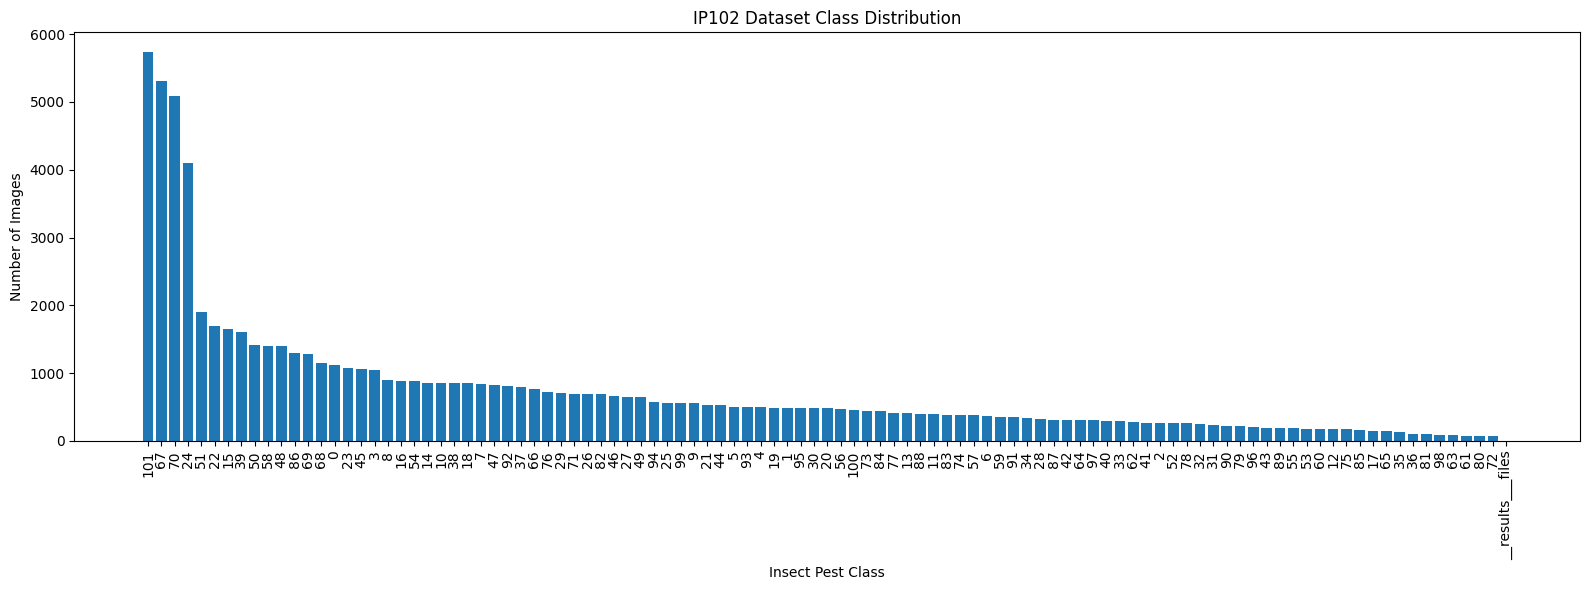


Checking image readability...


KeyboardInterrupt: 

In [19]:
# ================================================================
# IP102 INSECT PEST CLASSIFICATION PROJECT
# Complete Single-Cell Kaggle Implementation
# ================================================================
# Algorithms:
# 1. Custom CNN
# 2. ResNet50
# 3. EfficientNetB0
#
# Metrics:
# Accuracy, Precision, Recall, F1-score, ROC-AUC
#
# Additional outputs:
# Dataset statistics, preprocessing, 70:15:15 split,
# confusion matrices, performance graphs, CSV reports.
# ================================================================

import os
import sys
import gc
import json
import random
import warnings
from pathlib import Path
from collections import Counter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. INSTALL / IMPORT LIBRARIES
# ------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------

DATASET_CANDIDATES = [
    Path("/kaggle/input/ip02-dataset"),
    Path("/kaggle/input/notebooks/kushagranull/crop-yield-prediction"),
    Path("/kaggle/input")
]

OUTPUT_DIR = Path("/kaggle/working/IP102_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5
MAX_IMAGES = None  # None = use all discovered images

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# ------------------------------------------------
# 3. FIND THE DATASET AUTOMATICALLY
# ------------------------------------------------

print("\n" + "=" * 65)
print("SEARCHING FOR THE IP102 DATASET")
print("=" * 65)

image_roots = []

for candidate in DATASET_CANDIDATES:
    if not candidate.exists():
        print("Not found:", candidate)
        continue

    count = 0

    for p in candidate.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
            count += 1

    print(f"{candidate} -> {count} images")

    if count > 0:
        image_roots.append((candidate, count))

if not image_roots:
    raise FileNotFoundError(
        "No images found. In Kaggle, select Add Input and attach "
        "the IP102 dataset. Then rerun this cell."
    )

# Prefer the candidate containing the most images.
# If the same files are found through nested paths, use the
# broadest matching root rather than treating them as separate data.
image_roots.sort(key=lambda item: item[1], reverse=True)

DATASET_DIR = image_roots[0][0]

print("\nSelected dataset root:", DATASET_DIR)
print("Images discovered:", image_roots[0][1])

# ------------------------------------------------
# 4. FIND CLASSES AND IMAGE FILES
# ------------------------------------------------

all_images = sorted([
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

if MAX_IMAGES is not None:
    all_images = all_images[:MAX_IMAGES]

classes_files = list(DATASET_DIR.rglob("classes.txt"))

class_names_from_file = []

if classes_files:
    with open(classes_files[0], "r", encoding="utf-8") as f:
        class_names_from_file = [
            line.strip()
            for line in f
            if line.strip()
        ]

print("Class-name file found:", bool(classes_files))
print("Names in classes.txt:", len(class_names_from_file))

# The dataset may have folders such as:
# train/aphids/image.jpg
# test/aphids/image.jpg
#
# We identify class folders by looking for directories that
# directly contain images. Split folders such as train/test
# are not automatically treated as classes when their children
# contain the actual class folders.

image_dir_counts = {}

for image_path in all_images:
    image_dir_counts[image_path.parent] = (
        image_dir_counts.get(image_path.parent, 0) + 1
    )

class_dirs = []

for folder in image_dir_counts:
    name = folder.name.lower()

    if name in {"train", "test", "val", "valid", "validation"}:
        continue

    class_dirs.append(folder)

class_dir_names = sorted(set(p.name for p in class_dirs))

# If classes.txt names correspond to actual folder names,
# use their order to keep labels consistent.
if class_names_from_file:
    lookup = {
        name.lower(): name
        for name in class_names_from_file
    }

    matched_names = [
        lookup[name.lower()]
        for name in class_dir_names
        if name.lower() in lookup
    ]

    if matched_names:
        class_names = matched_names
    else:
        class_names = class_dir_names
else:
    class_names = class_dir_names

if len(class_names) < 2:
    raise ValueError(
        "Could not identify at least two image classes from folders. "
        "This code expects images organized in class-specific "
        "directories. If IP102 uses train.txt/test.txt label files, "
        "its annotation format must be parsed first."
    )

print("\nNumber of detected classes:", len(class_names))
print("First class names:", class_names[:15])

# ------------------------------------------------
# 5. CREATE IMAGE PATHS AND CLASS LABELS
# ------------------------------------------------

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

records = []

# Use the nearest ancestor whose directory name matches a class.
for image_path in all_images:

    label_name = None

    for parent in image_path.parents:
        if parent.name in class_to_index:
            label_name = parent.name
            break

    if label_name is not None:
        records.append({
            "image_path": str(image_path),
            "class_name": label_name,
            "label": class_to_index[label_name]
        })

data = pd.DataFrame(records)

if data.empty:
    raise ValueError(
        "Images were found, but no class folders matched the "
        "detected class names. Inspect the dataset structure."
    )

# Keep only classes with at least two images so a stratified
# split can be attempted where possible.
class_counts = data["label"].value_counts()

usable_labels = class_counts[class_counts >= 2].index

data = data[data["label"].isin(usable_labels)].reset_index(drop=True)

used_class_names = sorted(
    data["class_name"].unique(),
    key=lambda name: class_to_index[name]
)

class_to_index = {
    name: i for i, name in enumerate(used_class_names)
}

data["label"] = data["class_name"].map(class_to_index)

class_names = used_class_names
NUM_CLASSES = len(class_names)

print("\nDataset description")
print("-" * 50)
print("Total usable images:", len(data))
print("Number of classes:", NUM_CLASSES)
print("Unique image files:", data["image_path"].nunique())
print("Duplicate paths:", data["image_path"].duplicated().sum())

if NUM_CLASSES < 2:
    raise ValueError("At least two classes are required.")

# ------------------------------------------------
# 6. DATASET CLASS DISTRIBUTION
# ------------------------------------------------

distribution = (
    data["class_name"]
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Image_Count")
)

distribution.to_csv(
    OUTPUT_DIR / "class_distribution.csv",
    index=False
)

print("\nClass distribution:")
display(distribution)

plt.figure(figsize=(16, 6))

plt.bar(
    distribution["Class"],
    distribution["Image_Count"]
)

plt.title("IP102 Dataset Class Distribution")
plt.xlabel("Insect Pest Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "class_distribution.png",
    dpi=150
)

plt.show()

# ------------------------------------------------
# 7. IMAGE QUALITY AND MISSING-VALUE ANALYSIS
# ------------------------------------------------

print("\nChecking image readability...")

valid_paths = []
invalid_paths = []
image_sizes = []

for row in data.itertuples(index=False):
    path = Path(row.image_path)

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            image_sizes.append(img.size)

        valid_paths.append(row.image_path)

    except Exception:
        invalid_paths.append(row.image_path)

data = data[
    data["image_path"].isin(valid_paths)
].reset_index(drop=True)

print("Readable images:", len(valid_paths))
print("Corrupted or unreadable images:", len(invalid_paths))

with open(
    OUTPUT_DIR / "invalid_images.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(invalid_paths))

if not image_sizes:
    raise ValueError("No readable images remain.")

sizes_df = pd.DataFrame(
    image_sizes,
    columns=["Width", "Height"]
)

print("\nImage dimension statistics:")
display(sizes_df.describe())

print("\nMissing values:")
display(data.isnull().sum().to_frame("Missing_Count"))

# ------------------------------------------------
# 8. SPLIT DATA: 70% TRAIN, 15% VALIDATION, 15% TEST
# ------------------------------------------------

print("\nCreating stratified train/validation/test split...")

labels = data["label"].values

counts = Counter(labels)

if min(counts.values()) < 3:
    raise ValueError(
        "At least three images per class are required for this "
        "70:15:15 split. Some classes have too few images."
    )

train_df, remaining_df = train_test_split(
    data,
    test_size=0.30,
    random_state=SEED,
    stratify=data["label"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_df["label"]
)

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Testing"],
    "Images": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

split_summary["Percentage"] = (
    100 * split_summary["Images"] / len(data)
)

print("\nSplit summary:")
display(split_summary)

split_summary.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False
)

# ------------------------------------------------
# 9. PREPROCESSING WITH TENSORFLOW
# ------------------------------------------------

AUTOTUNE = tf.data.AUTOTUNE

def decode_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE]
    )

    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.int32)

    return image, label


def make_dataset(frame, training=False):

    paths = frame["image_path"].values
    labels = frame["label"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        decode_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# ------------------------------------------------
# 10. DISPLAY SAMPLE IMAGES
# ------------------------------------------------

sample_df = train_df.sample(
    n=min(12, len(train_df)),
    random_state=SEED
)

plt.figure(figsize=(12, 10))

for i, row in enumerate(sample_df.itertuples(index=False)):
    with Image.open(row.image_path) as img:
        img = img.convert("RGB")
        img.thumbnail((250, 250))

        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(row.class_name)
        plt.axis("off")

plt.suptitle("Sample IP102 Insect Images")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sample_images.png",
    dpi=150
)

plt.show()

# ------------------------------------------------
# 11. DEFINE THREE DIFFERENT CLASSIFICATION MODELS
# ------------------------------------------------

def build_custom_cnn():

    inputs = tf.keras.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    x = tf.keras.layers.Rescaling(1.0 / 255)(inputs)

    for filters in [32, 64, 128, 256]:

        x = tf.keras.layers.Conv2D(
            filters,
            kernel_size=3,
            padding="same",
            activation="relu"
        )(x)

        x = tf.keras.layers.BatchNormalization()(x)

        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dropout(0.4)(x)

    x = tf.keras.layers.Dense(
        256,
        activation="relu"
    )(x)

    x = tf.keras.layers.Dropout(0.3)(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_resnet50():

    base = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    base.trainable = False

    inputs = tf.keras.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    x = tf.keras.applications.resnet50.preprocess_input(inputs)

    x = base(x, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dropout(0.3)(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_efficientnet():

    base = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    base.trainable = False

    inputs = tf.keras.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    x = base(inputs, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dropout(0.3)(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model_builders = {
    "Custom_CNN": build_custom_cnn,
    "ResNet50": build_resnet50,
    "EfficientNetB0": build_efficientnet
}

# ------------------------------------------------
# 12. TRAIN AND EVALUATE MODELS
# ------------------------------------------------

all_results = []
histories = {}
trained_models = {}

for model_name, builder in model_builders.items():

    print("\n" + "=" * 65)
    print("TRAINING MODEL:", model_name)
    print("=" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    model = builder()

    checkpoint_path = OUTPUT_DIR / f"{model_name}_best.keras"

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=1e-6
        )
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    histories[model_name] = history.history

    # Reload the best validation-loss checkpoint.
    model = tf.keras.models.load_model(
        str(checkpoint_path)
    )

    trained_models[model_name] = model

    # Test evaluation.
    test_loss, test_accuracy = model.evaluate(
        test_ds,
        verbose=0
    )

    y_true = test_df["label"].values

    probabilities = model.predict(
        test_ds,
        verbose=1
    )

    y_pred = np.argmax(
        probabilities,
        axis=1
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    try:
        y_true_onehot = tf.keras.utils.to_categorical(
            y_true,
            num_classes=NUM_CLASSES
        )

        roc_auc = roc_auc_score(
            y_true_onehot,
            probabilities,
            average="macro",
            multi_class="ovr"
        )

    except Exception:
        roc_auc = np.nan

    result = {
        "Model": model_name,
        "Test_Loss": float(test_loss),
        "Accuracy": float(test_accuracy),
        "Precision_Macro": float(precision),
        "Recall_Macro": float(recall),
        "F1_Macro": float(f1),
        "ROC_AUC_Macro_OVR": float(roc_auc)
    }

    all_results.append(result)

    print("\nTest results for", model_name)

    for key, value in result.items():
        print(key, ":", value)

    # ------------------------------------------------
    # CONFUSION MATRIX
    # ------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(15, 12))

    sns.heatmap(
        cm,
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{model_name} - Test Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(rotation=90, fontsize=6)
    plt.yticks(rotation=0, fontsize=6)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{model_name}_confusion_matrix.png",
        dpi=150
    )

    plt.show()

    # ------------------------------------------------
    # CLASSIFICATION REPORT
    # ------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        OUTPUT_DIR / f"{model_name}_classification_report.csv"
    )

    print("\nClassification report:")
    display(report_df)

    # ------------------------------------------------
    # TRAINING AND VALIDATION GRAPHS
    # ------------------------------------------------

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    axes[0].plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    axes[0].set_title(f"{model_name} Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(
        history.history["loss"],
        label="Training Loss"
    )

    axes[1].plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    axes[1].set_title(f"{model_name} Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"{model_name}_training_graphs.png",
        dpi=150
    )

    plt.show()

    # Save predicted labels and probabilities for reproducibility.
    predictions_df = pd.DataFrame({
        "Image_Path": test_df["image_path"].values,
        "Actual_Class": [
            class_names[i] for i in y_true
        ],
        "Predicted_Class": [
            class_names[i] for i in y_pred
        ],
        "Correct": y_true == y_pred
    })

    predictions_df.to_csv(
        OUTPUT_DIR / f"{model_name}_predictions.csv",
        index=False
    )

# ------------------------------------------------
# 13. FINAL MODEL COMPARISON
# ------------------------------------------------

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

print("\n" + "=" * 65)
print("FINAL COMPARATIVE ANALYSIS")
print("=" * 65)

display(results_df)

# ------------------------------------------------
# 14. COMPARISON GRAPHS
# ------------------------------------------------

comparison_metrics = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "ROC_AUC_Macro_OVR"
]

for metric in comparison_metrics:

    plt.figure(figsize=(9, 5))

    values = results_df[metric]

    plt.bar(
        results_df["Model"],
        values
    )

    plt.title(f"Model Comparison: {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"comparison_{metric}.png",
        dpi=150
    )

    plt.show()

# ------------------------------------------------
# 15. SELECT THE BEST MODEL
# ------------------------------------------------

best_idx = results_df["F1_Macro"].idxmax()

best_model_name = results_df.loc[
    best_idx,
    "Model"
]

print("\nBest model based on macro F1-score:")
print(best_model_name)

print("\nBest model metrics:")
display(results_df.loc[[best_idx]])

# ------------------------------------------------
# 16. SAVE PROJECT SUMMARY
# ------------------------------------------------

summary = {
    "project": "IP102 Insect Pest Classification",
    "dataset_source": (
        "https://www.kaggle.com/datasets/rtlmhjbn/ip02-dataset"
    ),
    "selected_dataset_root": str(DATASET_DIR),
    "number_of_images": int(len(data)),
    "number_of_classes": int(NUM_CLASSES),
    "class_names": class_names,
    "train_images": int(len(train_df)),
    "validation_images": int(len(val_df)),
    "test_images": int(len(test_df)),
    "training_epochs": int(EPOCHS),
    "image_size": int(IMAGE_SIZE),
    "batch_size": int(BATCH_SIZE),
    "best_model_by_macro_f1": best_model_name,
    "results": all_results,
    "research_gaps": [
        "Long-tailed class distribution",
        "Visual similarity between pest species",
        "Generalization to real agricultural images",
        "Robustness to lighting and background variation",
        "Computational cost and deployment efficiency"
    ],
    "reference": (
        "Wu et al. (2019), IP102: A Large-Scale Benchmark Dataset "
        "for Insect Pest Recognition, CVPR, pp. 8787-8796."
    )
}

with open(
    OUTPUT_DIR / "project_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=4)

# ------------------------------------------------
# 17. SHOW ALL GENERATED FILES
# ------------------------------------------------

print("\n" + "=" * 65)
print("PROJECT EXECUTION FINISHED")
print("=" * 65)

print("Results directory:", OUTPUT_DIR)

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

print("\nDataset source:")
print("https://www.kaggle.com/datasets/rtlmhjbn/ip02-dataset")

print("\nOriginal research paper:")
print(
    "https://openaccess.thecvf.com/content_CVPR_2019/html/"
    "Wu_IP102_A_Large-Scale_Benchmark_Dataset_for_Insect_Pest_"
    "Recognition_CVPR_2019_paper.html"
)

print("\nIMPORTANT:")
print("Use actual output values in your final report.")
print("Do not report unmeasured accuracy or performance values.")

In [20]:
from pathlib import Path
from PIL import Image
import random

DATASET_DIR = Path("/kaggle/input")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
all_images = [
    p for p in DATASET_DIR.rglob("*")
    if p.suffix.lower() in image_extensions
]

print("Total images found:", len(all_images))

# Check a sample of 500 images
sample_images = random.sample(
    all_images, min(500, len(all_images))
)

corrupt_images = []

for path in sample_images:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        corrupt_images.append(str(path))

print("Images checked:", len(sample_images))
print("Corrupt images found:", len(corrupt_images))

Total images found: 75227
Images checked: 500
Corrupt images found: 0
